**90-minute homework / guided coding session · Fashion-MNIST · Chapter 11**

**What must change so a decoder can generate images from fresh random codes?**

An autoencoder can reconstruct a boot and still produce a poor image from a fresh random code.
Your goal is to implement the three changes that turn this problem into a VAE experiment:
a Gaussian encoder, a differentiable draw, and reconstruction plus KL.

Only **Tasks A, B, and C** require implementation. Data preparation, the decoder,
training, checks, checkpoints, plots, and controls are provided. You do not need the
previous homework's files. Familiarity with its encoder–decoder idea is enough.

| Clock | Focus | Stop when you have… |
|---|---|---|
| 0–10 min | Observe and prepare | A prediction and loaded data |
| 10–20 min | A · Gaussian encoder | Two unrestricted `(B, 2)` outputs |
| 20–30 min | B · Reparameterization | Passing checks and repeated posterior outputs |
| 30–45 min | C · Objective | Correct reductions and gradient checks |
| 45–60 min | Short training run | Separate reconstruction/KL measurements |
| 60–80 min | Controlled experiment | Fixed-image and fixed-prior comparisons |
| 80–90 min | Interpret and submit | One evidence figure and three short answers |

If a task blocks you for more than its allotted time, open its worked solution,
record that you used it, and continue. Interpretation matters more than hiding assistance.

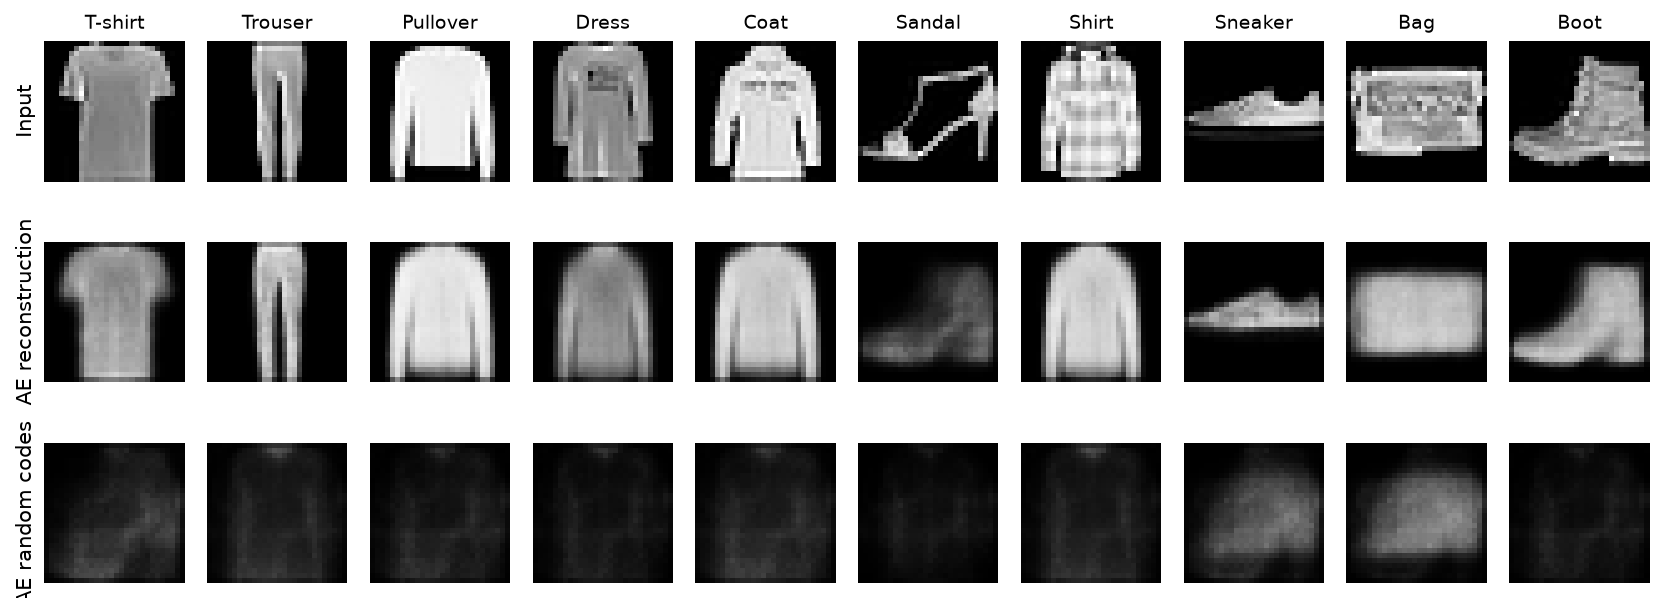

## 0 · Predict before coding · 0–10 min

**Predict:** why can the middle row look more plausible than the bottom row?
Name what the autoencoder was trained to do and what the random-code experiment asks it to do.

**Setup.** Open in Colab, or use a local Python environment with `torch`, `torchvision`,
`numpy`, `matplotlib`, and optionally `ipywidgets`. CPU is sufficient. Run the next
provided cell; it defines the support functions but does not train anything.
The notebook downloads Fashion-MNIST and about 3.5 MB of course checkpoints on first use.
For class, download the session ZIP and run the preparation cell before the timed session.
Extract the ZIP and open `starter/vae_lab.ipynb`; the adjacent assets work without a course-server connection.
Fashion-MNIST must still be downloaded once (or available through `COURSE_DATA_DIR`).

**Time protection:** the live run is limited to two small epochs or about 60 seconds
(checked after each batch). The comparison uses supplied 20-epoch models; you never
have to train the KL sweep. If setup fails, use the visual reading page with your
instructor and complete the code later; do not spend the session debugging downloads.

In [ ]:
"""Provided lab infrastructure, embedded verbatim in the student notebook.
No student TODOs: preparation, training, checkpoints, plots, and controls.
"""
import os, json, time, hashlib, urllib.request
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Ellipse
import torch
from torch import nn
from torch.nn import functional as F
from torchvision.datasets import FashionMNIST

SEED = 117
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
torch.set_num_threads(min(4, os.cpu_count() or 1))
OUT = Path(os.environ.get('COURSE_OUTPUT_DIR', 'vae-results'))
OUT.mkdir(parents=True, exist_ok=True)
DATA_DIR = os.environ.get('COURSE_DATA_DIR', 'data')
ASSET_URL = 'https://anassbelcaid.github.io/deeplearning-course/labs/11-variational-autoencoders/assets/'
NAMES = ['T-shirt', 'Trouser', 'Pullover', 'Dress', 'Coat',
         'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Boot']
BETAS = [0., 1., 20.]


def prepare_data():
    ds = FashionMNIST(DATA_DIR, train=True, download=True)
    permutation = torch.randperm(len(ds), generator=torch.Generator().manual_seed(41))
    train_ids, val_ids = permutation[:12000], permutation[12000:14000]
    # Keep only this session's 14,000 images in float32 memory.
    train_x = ds.data[train_ids].unsqueeze(1).float().div(255)
    val_x = ds.data[val_ids].unsqueeze(1).float().div(255)
    val_y = ds.targets[val_ids]
    selected = torch.stack([(val_y == k).nonzero()[0, 0] for k in range(10)])
    return train_x, val_x, val_y, selected, val_ids


class VAE(nn.Module):
    def __init__(self):
        super().__init__()
        self.encoder = GaussianEncoder()
        self.decoder = nn.Sequential(
            nn.Linear(2, 64), nn.ReLU(), nn.Linear(64, 128), nn.ReLU(),
            nn.Linear(128, 784), nn.Sigmoid(), nn.Unflatten(1, (1, 28, 28)))

    def forward(self, x):
        mu, logvar = self.encoder(x)
        return self.decoder(reparameterize(mu, logvar)), mu, logvar


def fresh_model():
    torch.manual_seed(SEED)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(SEED)
    return VAE().to(DEVICE)


def fit(model, train_x, val_x, beta=1., epochs=2, seconds=60., deterministic=False):
    """Time guard checked after each batch; validation uses a fixed noise stream."""
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
    loader_rng = torch.Generator().manual_seed(41)
    start = time.perf_counter()
    history, steps = [], 0
    for epoch in range(epochs):
        model.train()
        order = torch.randperm(len(train_x), generator=loader_rng)
        totals = np.zeros(3); seen = 0
        for ids in order.split(256):
            x = train_x[ids].to(DEVICE)
            optimizer.zero_grad(set_to_none=True)
            mu, lv = model.encoder(x)
            z = mu if deterministic else reparameterize(mu, lv)
            output = model.decoder(z)
            loss, rec, kl = vae_loss(output, x, mu, lv, beta)
            loss.backward(); optimizer.step()
            totals += np.array([loss.item(), rec.item(), kl.item()]) * len(x)
            seen += len(x); steps += 1
            if time.perf_counter() - start >= seconds:
                break
        stats = evaluate(model, val_x, deterministic=deterministic)
        history.append(dict(epoch=epoch+1, train_rec=float(totals[1]/seen),
                            train_kl=float(totals[2]/seen), **stats))
        print(f"epoch {epoch+1}: val reconstruction={stats['rec']:.2f}, KL={stats['kl']:.2f}", flush=True)
        if time.perf_counter() - start >= seconds:
            break
    return dict(history=history, seconds=time.perf_counter()-start,
                steps=steps, completed_epochs=len(history))


@torch.inference_mode()
def evaluate(model, x, deterministic=False):
    model.eval(); totals = np.zeros(2)
    rng = torch.Generator().manual_seed(811)
    for cpu_x in x.split(256):
        batch = cpu_x.to(DEVICE)
        mu, lv = model.encoder(batch)
        eps = torch.randn(mu.shape, generator=rng).to(DEVICE)
        z = mu if deterministic else reparameterize(mu, lv, eps)
        _, rec, kl = vae_loss(model.decoder(z), batch, mu, lv)
        totals += np.array([rec.item(), kl.item()])*len(batch)
    return dict(rec=float(totals[0]/len(x)), kl=float(totals[1]/len(x)))


def asset_file(relative):
    """Use local course files when available, otherwise the public course site."""
    explicit = os.environ.get('VAE_LAB_ASSETS')
    roots = ([Path(explicit)] if explicit else []) + [Path('assets'), Path('../assets'),
        Path('quarto-site/labs/11-variational-autoencoders/assets')]
    for root in roots:
        candidate = root/relative
        if candidate.is_file(): return candidate
    cache = OUT/'downloaded'/relative
    if not cache.exists():
        cache.parent.mkdir(parents=True, exist_ok=True)
        try:
            with urllib.request.urlopen(ASSET_URL+relative, timeout=30) as response:
                cache.write_bytes(response.read())
        except Exception as exc:
            raise RuntimeError('Course asset unavailable. Use the supplied session ZIP, '
                               'extract it, and open starter/vae_lab.ipynb.') from exc
    return cache


def load_reference_models():
    manifest = json.loads(asset_file('checkpoints/manifest.json').read_text())
    models = {}
    for key, record in manifest['models'].items():
        path = asset_file('checkpoints/'+record['file'])
        assert hashlib.sha256(path.read_bytes()).hexdigest() == record['sha256'], 'Checkpoint checksum mismatch'
        model = VAE().to(DEVICE)
        model.load_state_dict(torch.load(path, map_location=DEVICE, weights_only=True))
        model.eval(); models[key] = model
    return models, manifest


def save_figure(fig, filename):
    fig.savefig(OUT/filename, dpi=150, bbox_inches='tight', facecolor='white')
    plt.show(); plt.close(fig)


def image_rows(rows, labels, filename, titles=None):
    count = len(rows[0]); fig, axes = plt.subplots(len(rows), count,
        figsize=(max(9, count*1.12), len(rows)*1.5), squeeze=False)
    for r, row in enumerate(rows):
        for c, img in enumerate(row):
            ax = axes[r,c]; ax.imshow(img.detach().cpu().squeeze(), cmap='gray', vmin=0, vmax=1)
            ax.set_xticks([]); ax.set_yticks([])
            for spine in ax.spines.values(): spine.set_visible(False)
            if c == 0: ax.set_ylabel(labels[r], fontsize=10)
            if r == 0 and titles: ax.set_title(titles[c], fontsize=9)
    fig.tight_layout(); save_figure(fig, filename)


@torch.inference_mode()
def opening_gallery(ae, val_x, selected):
    x = val_x[selected].to(DEVICE)
    mu, _ = ae.encoder(x)
    prior = torch.randn((10,2), generator=torch.Generator().manual_seed(91)).to(DEVICE)
    image_rows([x, ae.decoder(mu), ae.decoder(prior)],
        ['Input', 'AE reconstruction', 'AE random codes'], 'opening.png', NAMES)


@torch.inference_mode()
def posterior_view(model, val_x, selected, category=9, draw_seed=8, filename='posterior.png'):
    x = val_x[selected[category]:selected[category]+1].to(DEVICE)
    mu, lv = model.encoder(x)
    eps = torch.randn((8,2), generator=torch.Generator().manual_seed(draw_seed)).to(DEVICE)
    z = reparameterize(mu.expand(8,-1), lv.expand(8,-1), eps)
    images = torch.cat([x, model.decoder(mu), model.decoder(z)])
    image_rows([images], ['Same input'], filename,
        ['Input', 'Decode μ']+[f'Draw {i+1}' for i in range(8)])
    fig, ax = plt.subplots(figsize=(7,4.5))
    mean = mu.cpu().numpy()[0]; sigma = (lv*.5).exp().cpu().numpy()[0]
    ax.add_patch(Ellipse(mean, 2*sigma[0], 2*sigma[1], facecolor='#5599bb', alpha=.15))
    points = z.cpu().numpy()
    ax.scatter(*points.T, color='#bd573e', label='8 posterior draws')
    ax.scatter(*mean, marker='x', s=80, color='black', label='Posterior mean')
    for i, point in enumerate(points): ax.annotate(str(i+1), point, xytext=(4,4), textcoords='offset points')
    ax.set(xlim=(mean[0]-3*sigma[0],mean[0]+3*sigma[0]),
           ylim=(mean[1]-3*sigma[1],mean[1]+3*sigma[1]), xlabel='z₁',ylabel='z₂',
           title=f'{NAMES[category]}: μ={mean.round(2)}, σ={sigma.round(2)}')
    ax.legend(loc='best'); fig.tight_layout()
    save_figure(fig, filename.replace('.png','-cloud.png'))


@torch.inference_mode()
def prior_view(model, draw_seed=91, filename='prior-draw.png'):
    z = torch.randn((10,2), generator=torch.Generator().manual_seed(draw_seed)).to(DEVICE)
    image_rows([model.decoder(z)], ['Prior → decoder'], filename,
               [f'({a:.1f}, {b:.1f})' for a,b in z.cpu().tolist()])


@torch.inference_mode()
def comparison(models, val_x, val_y, selected):
    x = val_x[selected].to(DEVICE)
    prior = torch.randn((10,2), generator=torch.Generator().manual_seed(91)).to(DEVICE)
    recons, samples, labels, means, draws = [x], [], ['Input'], [], []
    for beta in BETAS:
        model = models[f'beta{beta:g}']; mu, lv = model.encoder(x)
        recons.append(model.decoder(mu)); labels.append(f'β = {beta:g}')
        samples.append(model.decoder(prior))
        all_mu, all_lv = model.encoder(val_x[:600].to(DEVICE))
        noise = torch.randn(all_mu.shape, generator=torch.Generator().manual_seed(81)).to(DEVICE)
        means.append(all_mu.cpu().numpy())
        draws.append(reparameterize(all_mu, all_lv, noise).cpu().numpy())
    image_rows(recons, labels, 'reconstructions.png', NAMES)
    image_rows(samples, labels[1:], 'prior-comparison.png', [f'z {i+1}' for i in range(10)])
    # Shared axes include every displayed point and the reference prior region.
    bound = max(3.5, float(np.abs(np.concatenate(means+draws)).max())*1.05)
    fig, axes = plt.subplots(2,3,figsize=(12,8),sharex=True,sharey=True)
    for j,beta in enumerate(BETAS):
        for r, points in enumerate([means[j], draws[j]]):
            ax = axes[r,j]
            ax.scatter(*points.T,c=val_y[:600],cmap='tab10',vmin=-.5,vmax=9.5,s=7,alpha=.5)
            ax.add_patch(plt.Circle((0,0),2.45,fill=False,color='black',ls='--'))
            ax.set(xlim=(-bound,bound),ylim=(-bound,bound),aspect='equal',xlabel='z₁',ylabel='z₂',
                   title=f'β={beta:g} · '+('posterior means' if r==0 else 'posterior draws'))
    fig.suptitle('Same 600 validation images · shared axes · dashed circle: 95% prior mass',fontsize=13)
    fig.tight_layout(); save_figure(fig,'latent-maps.png')
    # The unregularized codes set a much larger scale. A labeled second view
    # preserves the overview while making the regularized distributions legible.
    bound = max(3.5, float(np.abs(np.concatenate(means[1:]+draws[1:])).max())*1.05)
    fig, axes = plt.subplots(2,2,figsize=(9,8),sharex=True,sharey=True)
    for j,beta in enumerate(BETAS[1:]):
        for r,points in enumerate([means[j+1],draws[j+1]]):
            ax=axes[r,j]
            ax.scatter(*points.T,c=val_y[:600],cmap='tab10',vmin=-.5,vmax=9.5,s=9,alpha=.5)
            ax.add_patch(plt.Circle((0,0),2.45,fill=False,color='black',ls='--'))
            ax.set(xlim=(-bound,bound),ylim=(-bound,bound),aspect='equal',xlabel='z₁',ylabel='z₂',
                   title=f'β={beta:g} · '+('posterior means' if r==0 else 'posterior draws'))
    handles=[plt.Line2D([],[],marker='o',ls='',color=plt.cm.tab10(i),label=name)
             for i,name in enumerate(NAMES)]
    fig.legend(handles=handles,loc='lower center',ncol=5,fontsize=9)
    fig.suptitle('Regularized models · closer view · same points, new shared axes',fontsize=12)
    fig.tight_layout(rect=(0,.065,1,.97)); save_figure(fig,'latent-zoom.png')


@torch.inference_mode()
def latent_use(models, val_x):
    """Deterministic decode-mean probe; separate from stochastic ELBO evaluation."""
    x=val_x.to(DEVICE)
    order=torch.randperm(len(x),generator=torch.Generator().manual_seed(31)).to(DEVICE)
    scores=[]
    for beta in BETAS:
        model=models[f'beta{beta:g}']; mu,_=model.encoder(x)
        matched=F.binary_cross_entropy(model.decoder(mu),x,reduction='none').flatten(1).sum(1).mean().item()
        shuffled=F.binary_cross_entropy(model.decoder(mu[order]),x,reduction='none').flatten(1).sum(1).mean().item()
        scores.append(dict(beta=beta,matched=matched,shuffled=shuffled,gap=shuffled-matched))
    fig,ax=plt.subplots(figsize=(8,4)); loc=np.arange(3)
    ax.bar(loc-.17,[s['matched'] for s in scores],.34,label='Matched μ',color='#4c91ad')
    ax.bar(loc+.17,[s['shuffled'] for s in scores],.34,label='Shuffled μ',color='#ce7154')
    ax.set(xticks=loc,xticklabels=[f'β={b:g}' for b in BETAS],ylabel='Mean pixel-summed BCE',
           title='Does assigning the right image-specific code matter?')
    ax.legend(); fig.tight_layout(); save_figure(fig,'latent-use.png')
    return scores


def training_curves(manifest):
    fig,axes=plt.subplots(1,2,figsize=(11,4))
    for beta,color in zip(BETAS,['#4c91ad','#ce7154','#84669d']):
        history=manifest['models'][f'beta{beta:g}']['history']
        for ax,key in zip(axes,['rec','kl']):
            ax.plot([h['epoch'] for h in history],[h[key] for h in history],label=f'β={beta:g}',color=color)
    for ax,title in zip(axes,['Validation reconstruction cost','Validation KL per image']):
        ax.set(xlabel='Epoch',ylabel='Nats / image',title=title); ax.legend()
    fig.tight_layout(); save_figure(fig,'training-curves.png')


def controls(models, val_x, selected):
    """Optional controls; equivalent static function calls always work."""
    try:
        import ipywidgets as w
        from IPython.display import display, clear_output
        model_select=w.Dropdown(options=[('β = '+str(b),f'beta{b:g}') for b in BETAS],value='beta1',description='Model')
        garment=w.Dropdown(options=list(zip(NAMES,range(10))),value=9,description='Input')
        posterior=w.Button(description='Resample posterior'); prior=w.Button(description='Draw from prior')
        output=w.Output(); state={'seed':8}
        def update(kind):
            state['seed']+=1
            with output:
                clear_output(wait=True)
                print('Weights fixed. New random draw; posterior also uses the selected input.')
                model=models[model_select.value]
                if kind=='posterior': posterior_view(model,val_x,selected,garment.value,state['seed'],'interactive-posterior.png')
                else: prior_view(model,state['seed'],'interactive-prior.png')
        posterior.on_click(lambda _: update('posterior'))
        prior.on_click(lambda _: update('prior'))
        display(w.VBox([w.HBox([model_select,garment]),w.HBox([posterior,prior]),output]))
        return dict(model=model_select,garment=garment,posterior=posterior,prior=prior,output=output)
    except ImportError:
        print('Widgets unavailable: use posterior_view(...) and prior_view(...) below.')

In [ ]:
train_x, val_x, val_y, selected, val_ids = prepare_data()
print('Training:', tuple(train_x.shape), '| Validation:', tuple(val_x.shape))
print('Device:', DEVICE)

**Expected:** `(12000, 1, 28, 28)` training and `(2000, 1, 28, 28)` validation.
A fixed permutation (seed 41) selects disjoint subsets of the official training split.
The official test split is unused: this session investigates mechanisms, not final performance.
Labels are only used to choose and color inspection examples. They never enter the loss.

## 1 · A distribution instead of one code · 10–20 min

The provided `VAE` owns an encoder and decoder. Your encoder owns a shared feature
extractor and **two different linear heads**. The decoder structure is already familiar.

### Task A · Complete the Gaussian encoder

**Given:** `features(x)` has shape `(B, 64)` and the latent dimension is 2.
**Implement:** two independent `nn.Linear(64, 2)` heads and return `(mu, logvar)`.
Both outputs are unrestricted real values. Do not add Sigmoid, ReLU, or sampling here.
`logvar` represents $\log\sigma^2$, not $\sigma$ or $\log\sigma$.

> **PAUSE · 7 minutes.** Trace the diagram into module attributes before editing the code.

In [ ]:
class GaussianEncoder(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Flatten(), nn.Linear(784, 128), nn.ReLU(),
            nn.Linear(128, 64), nn.ReLU())
        # TODO A: create self.mu and self.logvar as separate heads.
        raise NotImplementedError('Task A: create the two heads')

    def forward(self, x):
        h = self.features(x)
        # TODO A: return both head outputs, with no output activation.
        raise NotImplementedError('Task A: return mu, logvar')

<details>
<summary>Worked solution · open after your attempt</summary>

```python
class GaussianEncoder(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Flatten(), nn.Linear(784, 128), nn.ReLU(),
            nn.Linear(128, 64), nn.ReLU())
        self.mu = nn.Linear(64, 2)
        self.logvar = nn.Linear(64, 2)

    def forward(self, x):
        h = self.features(x)
        return self.mu(h), self.logvar(h)
```

</details>

In [ ]:
encoder = GaussianEncoder()
mu, logvar = encoder(torch.zeros(4, 1, 28, 28))
assert mu.shape == logvar.shape == (4, 2)
assert encoder.mu is not encoder.logvar
assert encoder.mu.weight.data_ptr() != encoder.logvar.weight.data_ptr()
# Heads must be able to emit negative means AND positive log variances.
with torch.no_grad():
    encoder.mu.weight.zero_(); encoder.mu.bias.fill_(-2.)
    encoder.logvar.weight.zero_(); encoder.logvar.bias.fill_(1.)
a, b = encoder(torch.zeros(4, 1, 28, 28))
torch.testing.assert_close(a, torch.full_like(a, -2.))
torch.testing.assert_close(b, torch.ones_like(b))
print('PASS A: shapes, separate parameters, unrestricted outputs')

## 2 · Draw a code without cutting the gradient · 20–30 min

### Task B · Reparameterize

**Given:** `mu`, `logvar`, and optional fixed standard-normal noise `eps`, all shaped `(B, 2)`.
**Implement:** $z=\mu+\exp(\tfrac12\,\mathrm{logvar})\odot\epsilon$.
If `eps` is absent, create it with `torch.randn_like(mu)`; otherwise use the supplied values.
Preserve dtype, device, and the gradient path. Do not detach or convert to NumPy.

> **PAUSE · 5 minutes.** First work out why a variance of 4 must multiply noise by 2, not 4.

In [ ]:
def reparameterize(mu, logvar, eps=None):
    # TODO B: draw noise only if needed, then shift and scale it.
    raise NotImplementedError('Task B')

<details>
<summary>Worked solution · open after your attempt</summary>

```python
def reparameterize(mu, logvar, eps=None):
    if eps is None:
        eps = torch.randn_like(mu)
    return mu + torch.exp(0.5 * logvar) * eps
```

</details>

In [ ]:
mu = torch.tensor([[1., -1.]], requires_grad=True)
lv = torch.tensor([[4., .25]]).log().requires_grad_()
eps = torch.tensor([[.5, -2.]])
z = reparameterize(mu, lv, eps)
torch.testing.assert_close(z, torch.tensor([[2., -2.]]))
g_mu, g_lv = torch.autograd.grad(z.sum(), (mu, lv))
torch.testing.assert_close(g_mu, torch.ones_like(mu))
torch.testing.assert_close(g_lv, torch.tensor([[.5, -.5]]))
assert z.dtype == mu.dtype and z.device == mu.device
samples = reparameterize(torch.zeros(20000, 2), torch.zeros(20000, 2))
assert samples.mean().abs() < .04 and abs(samples.std().item()-1) < .04
print('PASS B: fixed-noise arithmetic, gradient paths, standard-normal sampling')
models, manifest = load_reference_models()
posterior_view(models['beta1'], val_x, selected, category=9, draw_seed=8)

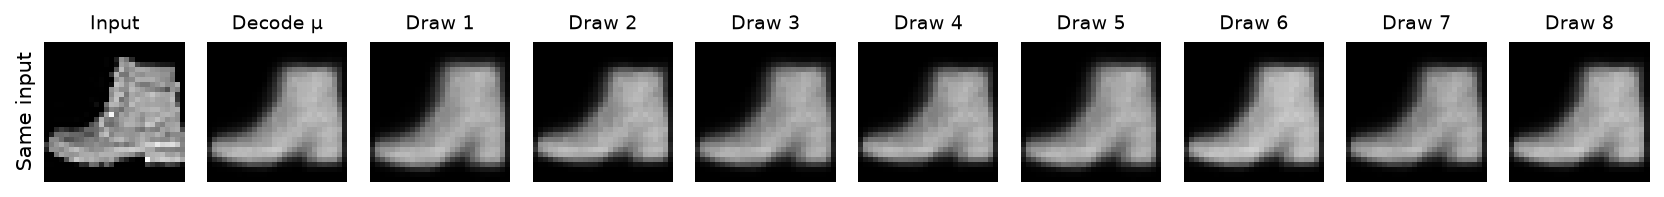

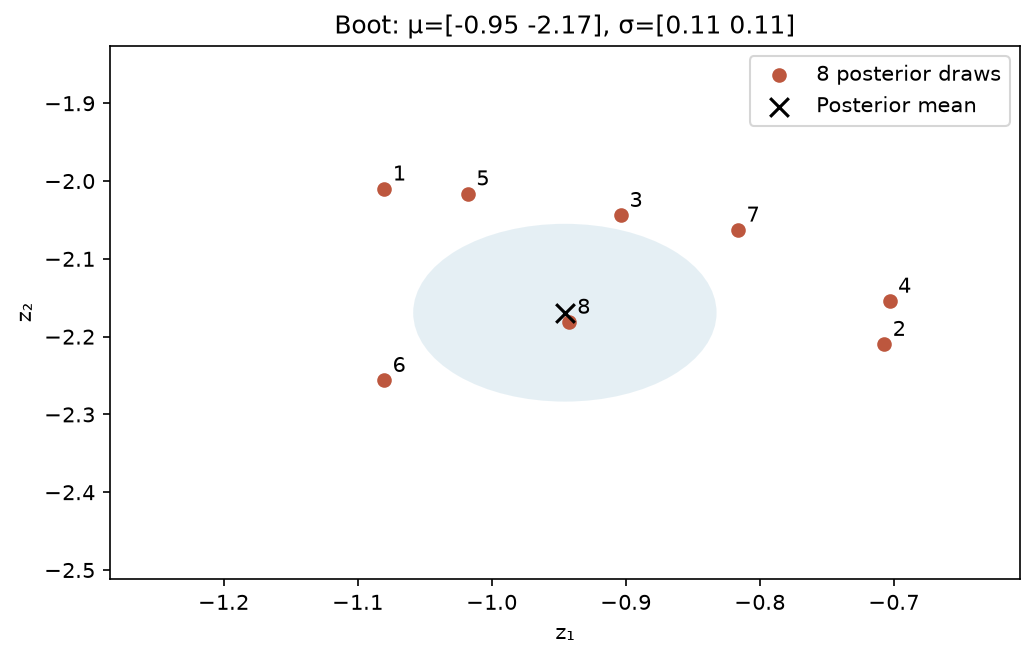

**Interpret:** the weights and input stayed fixed. Only the noise changed. Decoding the
posterior mean is deterministic here, but it is not generally the expected decoded image.
`eval()` does not disable a random draw written explicitly in the forward method.
The modest visible variation in this example is evidence to inspect, not a promise
that every input has equally varied outputs.

## 3 · Make the training objective precise · 30–45 min

### Task C · Reconstruction and KL

**Given:** `x_hat, x` shaped `(B, 1, 28, 28)`; `mu, logvar` shaped `(B, 2)`.
**Return three scalars:** mean total loss, mean reconstruction cost, and mean **unweighted** KL.

$$
\begin{aligned} R_i&=\sum_{p=1}^{784}\operatorname{BCE}(\hat x_{ip},x_{ip}),\\
K_i&=\frac12\sum_{j=1}^2(\mu_{ij}^2+e^{\ell_{ij}}-1-\ell_{ij}),\\
L&=\frac1B\sum_i(R_i+\beta K_i).\end{aligned}
$$

Sum over each image's pixels and latent coordinates **before** averaging over images.
A pixel-mean reconstruction term would be 784 times smaller and would change the effective
KL weight. Fractional Fashion-MNIST intensities are soft BCE targets; this is the course's
reconstruction convention, not an exact continuous-pixel likelihood model.
At $\beta=1$ this is the usual VAE objective under that convention; other weights are
controlled ablations and should not all be called the standard negative ELBO.

> **PAUSE · 9 minutes.** Annotate the shape after each reduction. Keep KL unweighted in the reported metric.

In [ ]:
def vae_loss(x_hat, x, mu, logvar, beta=1.0):
    # TODO C: per-image reconstruction and KL, then batch means.
    raise NotImplementedError('Task C')

<details>
<summary>Worked solution · open after your attempt</summary>

```python
def vae_loss(x_hat, x, mu, logvar, beta=1.0):
    rec = F.binary_cross_entropy(x_hat, x, reduction='none')
    rec = rec.flatten(1).sum(1)
    kl = 0.5 * (mu.square() + logvar.exp() - 1 - logvar).sum(1)
    return (rec + beta * kl).mean(), rec.mean(), kl.mean()
```

</details>

In [ ]:
x = torch.zeros(2, 1, 28, 28)
x_hat = torch.full_like(x, .5)
mu = torch.tensor([[1., 0.], [0., 2.]])
lv = torch.zeros_like(mu)
loss, rec, kl = vae_loss(x_hat, x, mu, lv, beta=2.)
torch.testing.assert_close(rec, torch.tensor(784*np.log(2), dtype=rec.dtype))
torch.testing.assert_close(kl, torch.tensor(1.25))
torch.testing.assert_close(loss, rec + 2*kl)
assert vae_loss(x_hat,x,torch.zeros_like(mu),lv)[2].item() == 0.
for a,b in zip(vae_loss(x_hat,x,mu,lv,2.),
               vae_loss(*[torch.cat([v,v]) for v in [x_hat,x,mu,lv]],beta=2.)):
    torch.testing.assert_close(a,b)
# Non-unit variance catches omitted exp(logvar) and incorrect signs.
variance_kl = vae_loss(x_hat,x,torch.zeros_like(mu),torch.full_like(mu,np.log(4)))[2]
torch.testing.assert_close(variance_kl, torch.tensor(3-np.log(4),dtype=variance_kl.dtype))
model = fresh_model()
batch = train_x[:16].to(DEVICE)
x_hat, mu, lv = model(batch)
_, reconstruction, _ = vae_loss(x_hat,batch,mu,lv)
grads = torch.autograd.grad(reconstruction,
    [model.encoder.mu.weight, model.encoder.logvar.weight])
assert all(torch.isfinite(g).all() and g.abs().sum()>0 for g in grads)
print('PASS C: reductions, KL cases, batch duplication, reconstruction gradients to both heads')

**Numerical check:** reconstruction is about **543.43**, KL is **1.25**, and the
β=2 total is about **545.93**. Duplicating the batch leaves all three means unchanged.
A nonzero KL gradient alone would not prove that reconstruction can train both heads;
the final check therefore differentiates reconstruction alone.

## 4 · Run the mechanism you implemented · 45–60 min

Run the provided training cell. It creates a fresh model using **your three implementations**.
The short run uses 4,096 training and 512 validation images. It verifies learning and
produces an early gallery; it is not expected to match the longer reference models.
Read `fit` in the folded support cell if you want to trace zeroing gradients, backward,
and the optimizer step. There is no training-loop implementation task.

In [ ]:
live_model = fresh_model()
live_run = fit(live_model, train_x[:4096], val_x[:512], beta=1., epochs=2, seconds=60.)
with torch.inference_mode():
    examples = val_x[selected].to(DEVICE)
    mu, _ = live_model.encoder(examples)
    image_rows([examples, live_model.decoder(mu)],
               ['Input', 'Short live run'], 'my-short-run.png', NAMES)
print('Measured seconds:', round(live_run['seconds'], 2), '| updates:', live_run['steps'])

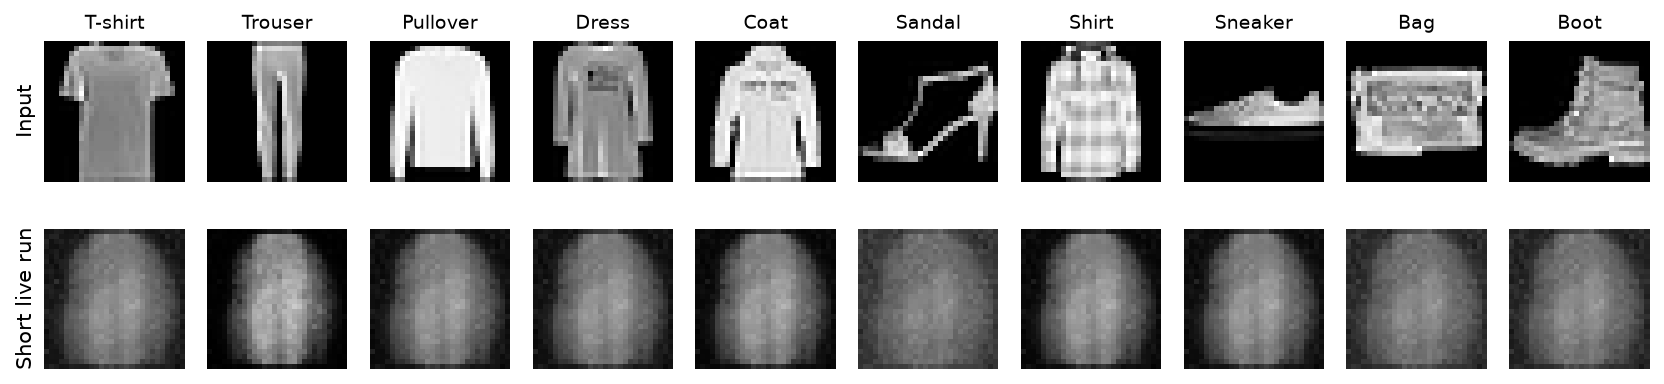

**Recorded timing on the reference machine:** 0.1 seconds for
32 optimizer updates on cpu with PyTorch 2.13.0+cu130.
Hardware and download times vary. The timer excludes data preparation; its stop is checked
between batches and a final validation pass adds a little time. If computation is slow,
continue with the supplied checkpoints. No marks depend on runtime or image sharpness.

**Discuss:** which term is larger? Does a falling total alone tell you whether KL is being ignored?
Do not compare the short-run score with the 20-epoch score as if their training budgets matched.

## 5 · A controlled KL experiment · 60–80 min

**Before running:** predict how β=0, 1, and 20 might affect reconstruction, prior samples,
and dependence on the input. Then run the provided cells and revise your prediction.

All three reference models use the same architecture, initial parameter values, training
split, shuffled-batch stream, 20-epoch budget, and optimizer settings. β=0 still samples
from an encoder distribution: it is an **unregularized stochastic autoencoder**, distinct
from the deterministic AE in the opening. These are single-seed experiments.

The reconstruction galleries decode **posterior means** to remove sampling noise.
The reported validation reconstruction cost instead uses one fixed posterior draw per image.
The prior gallery uses identical latent coordinates across models, although a given coordinate
need not acquire the same semantic meaning after different training runs.

In [ ]:
comparison(models, val_x, val_y, selected)
training_curves(manifest)
probe_scores = latent_use(models, val_x)
for beta in BETAS:
    key = f'beta{beta:g}'
    print(key, evaluate(models[key], val_x))
print('Matched/shuffled mean-code probe:', probe_scores)

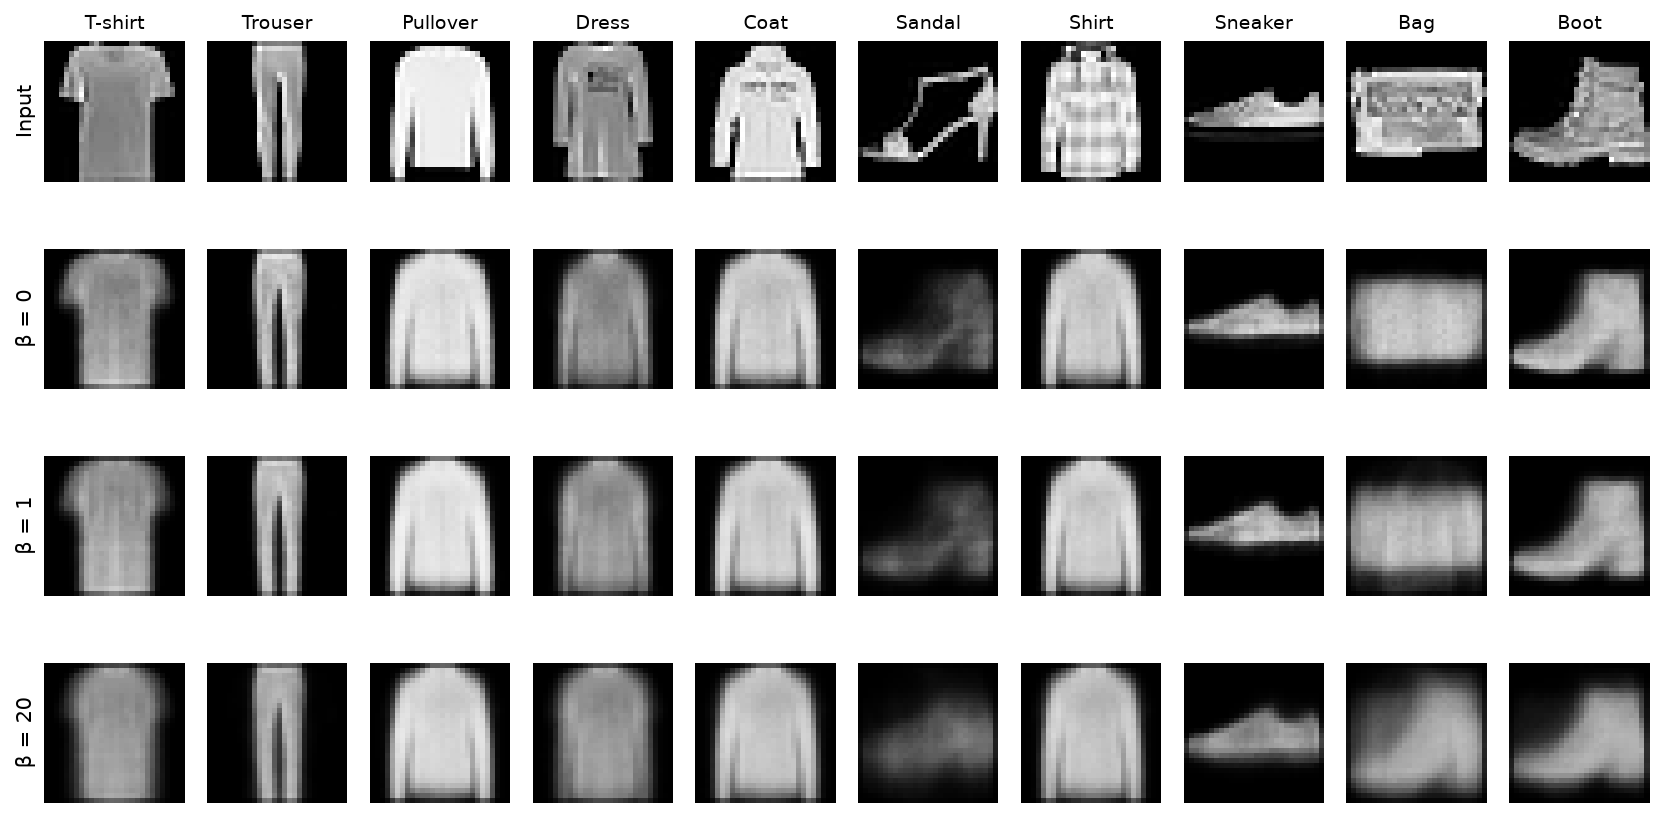

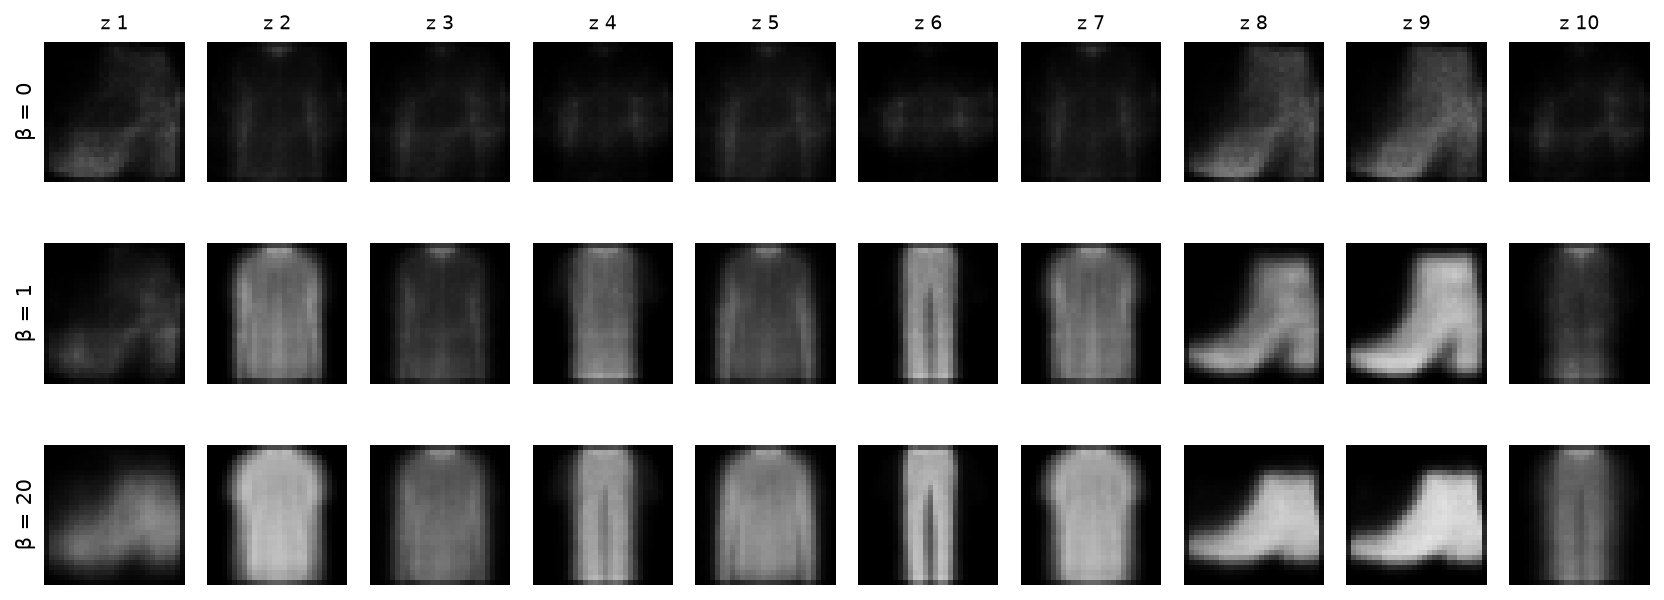

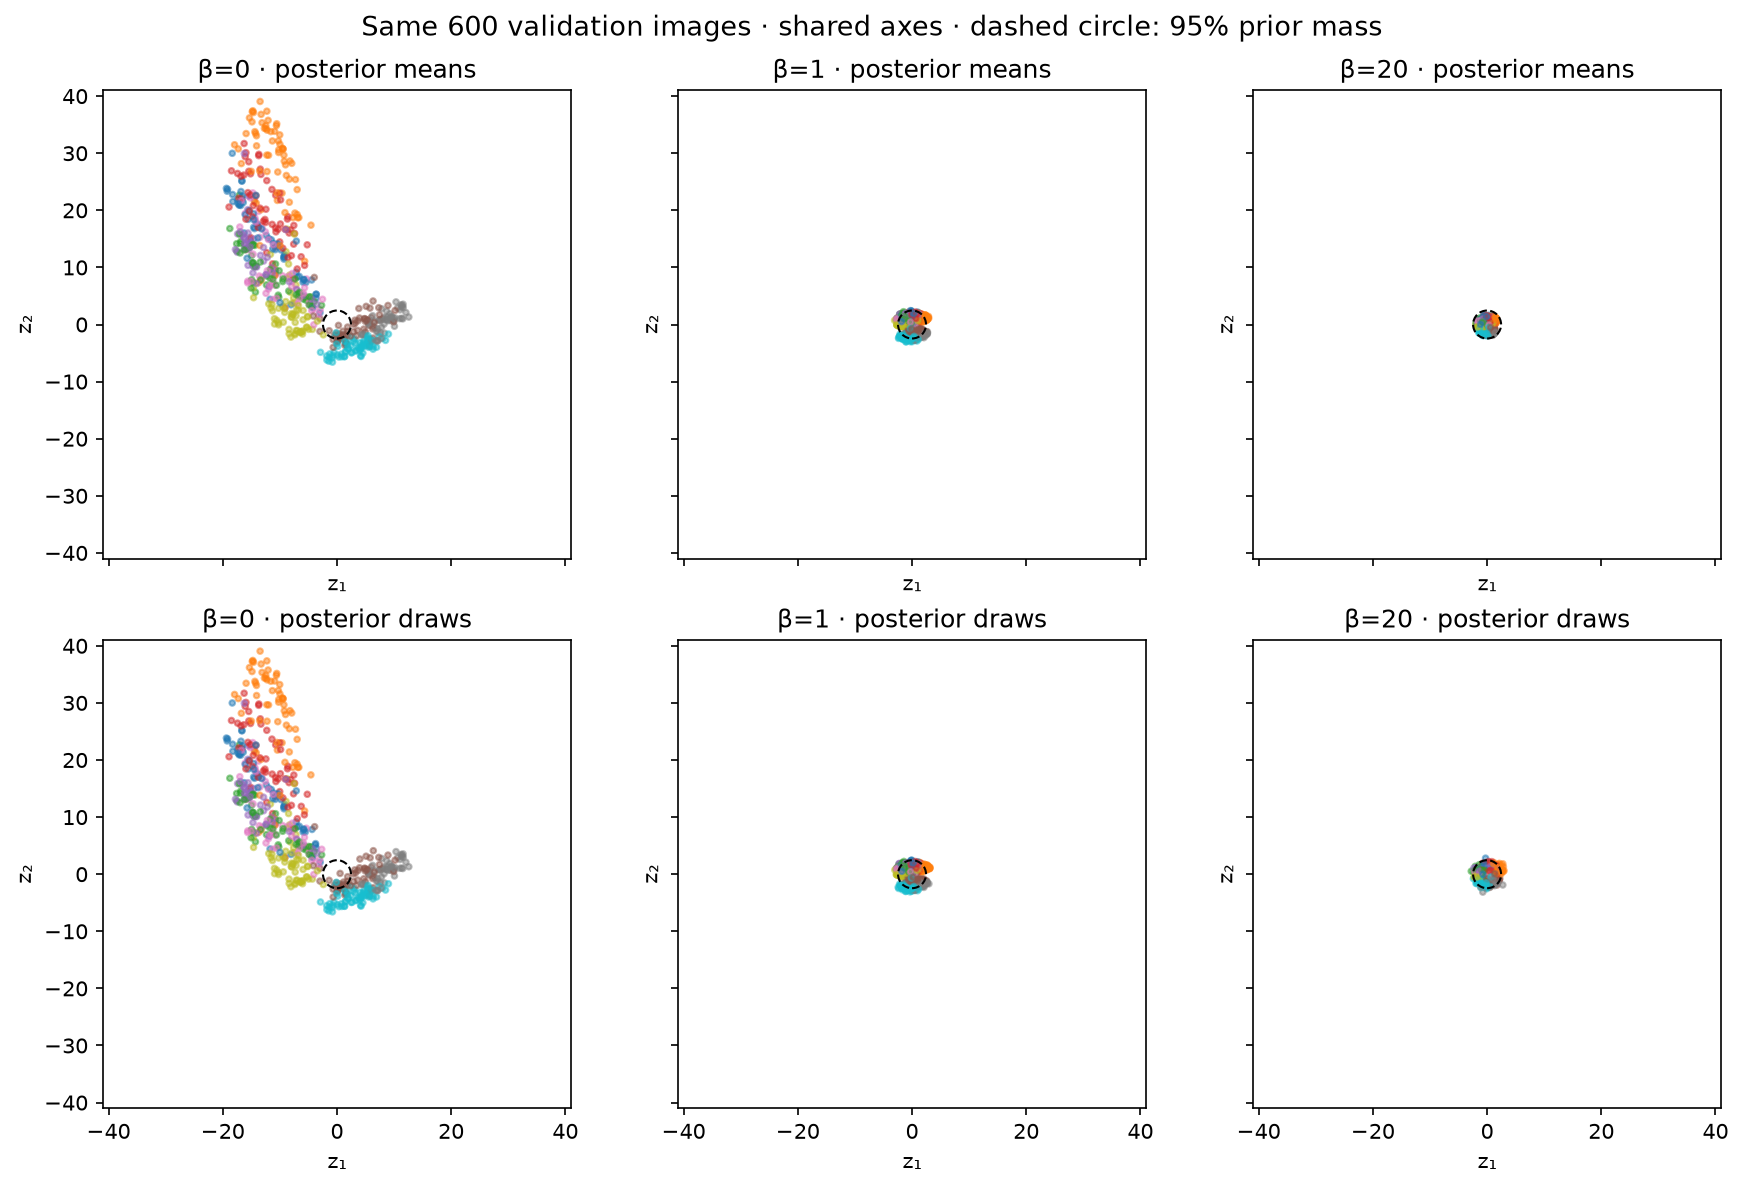

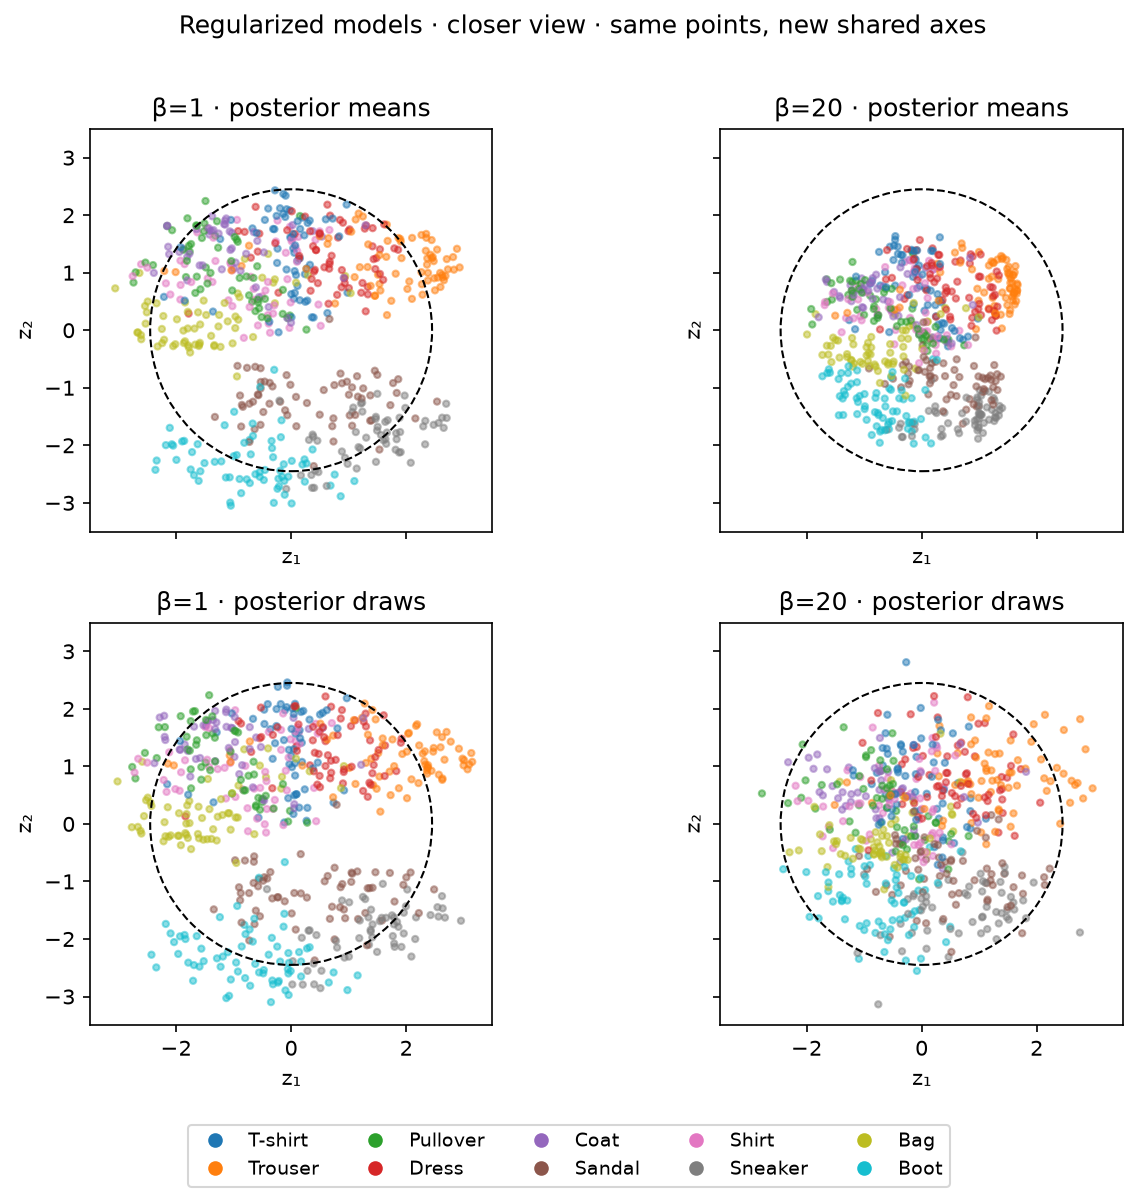

**Read the maps carefully:** a cluster of means near zero does not imply that posterior
draws have zero spread. Nor does a visually prior-like cloud establish that codes carry
useful image information. These panels separate the two questions; they are not PCA views.

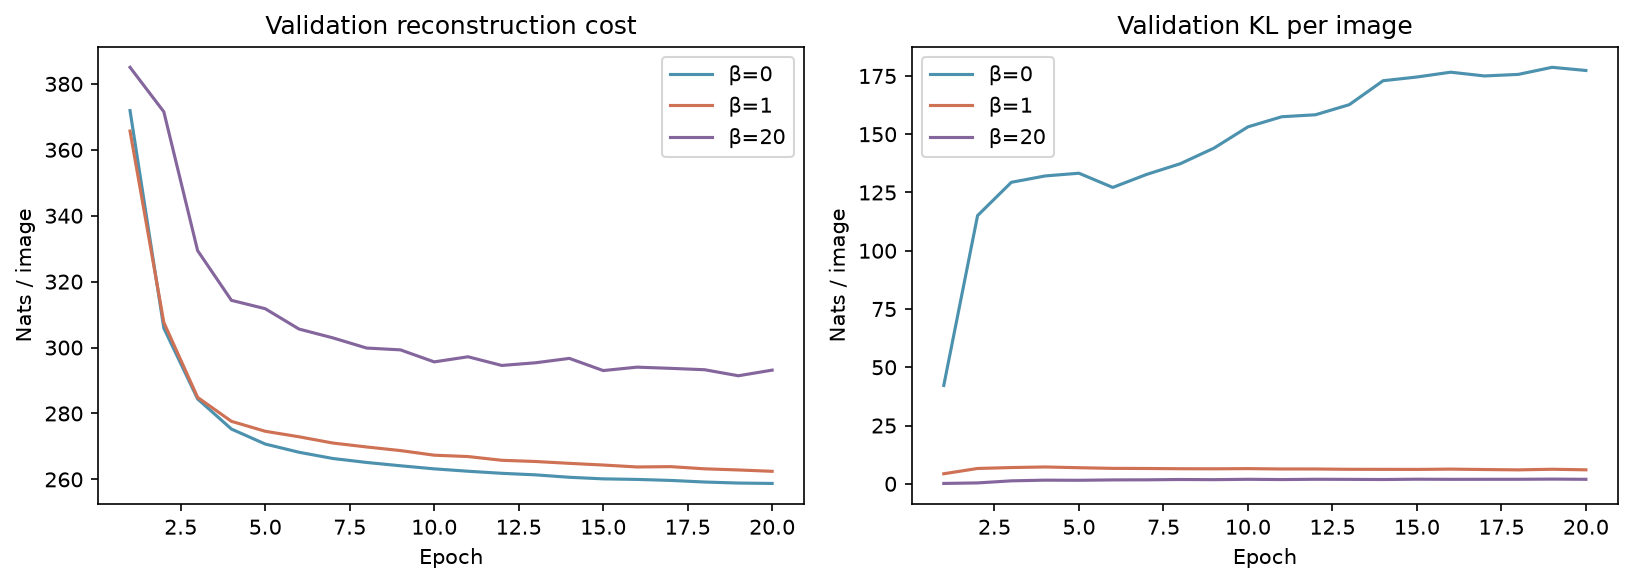

| β | Validation reconstruction | Validation KL | Matched μ BCE | Shuffled μ BCE |
|---:|---:|---:|---:|---:|
| 0 | 258.77 | 177.35 | 258.77 | 887.05 |
| 1 | 262.45 | 6.00 | 261.29 | 745.79 |
| 20 | 293.15 | 1.93 | 275.56 | 552.69 |

All costs are pixel-summed/latent-summed, averaged over 2,000 validation images. These are reference observations, not targets to match.

![A separate deterministic probe: decode each image’s own posterior mean, then assign shuffled means to the same targets. A small penalty for shuffling is evidence to investigate weak image-specific latent use; it is not by itself a proof of complete posterior collapse.](attachment:latent-use.png)
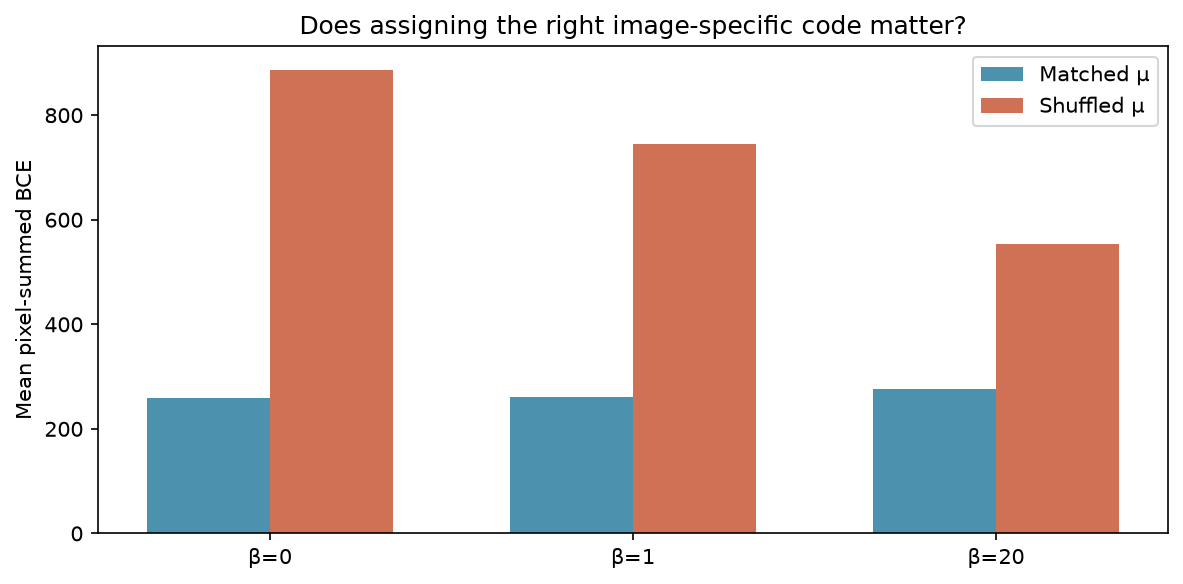

<details>
<summary>Interpretation checkpoint · open after comparing the panels</summary>

In this recorded run, β=0 reconstructs well but its codes are far from the prior region,
and fresh prior outputs are poor. β=1 makes the prior draws more useful with a modest
reconstruction cost increase. β=20 reduces KL and produces blurrier reconstructions,
but shuffling its mean codes still substantially increases reconstruction cost:
**these results do not show complete posterior collapse**. A stronger penalty does not
automatically imply that the model ignores its input. Cite the actual probe and images.

</details>

### Try changing only the random draw

Run the controls, choose a model and input, then click **Resample posterior**.
Use **Draw from prior** to remove the input entirely. Weights stay fixed.
Widgets are optional: the static calls below provide the same experiment everywhere.

In [ ]:
lab_controls = controls(models, val_x, selected)
# Static equivalents; change category (0–9) or draw_seed and rerun.
posterior_view(models['beta1'], val_x, selected, category=9, draw_seed=9,
               filename='my-posterior.png')
prior_view(models['beta1'], draw_seed=92, filename='my-prior.png')

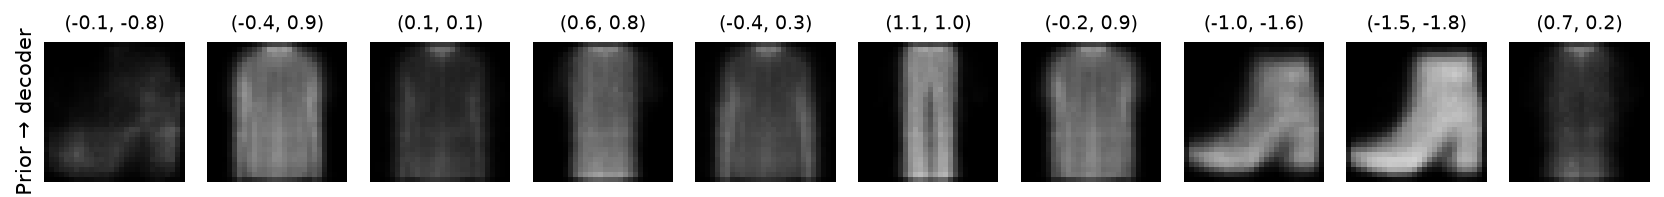

## 6 · Submit evidence, not a training marathon · 80–90 min

Submit this notebook with A–C completed, all checks passing, and visible outputs from the
short run (or a recorded reason for using the checkpoint fallback). Use **Restart & Run All**
after editing; all later cells use provided infrastructure. Keep the data and checkpoints
out of your submission.

Attach **one figure with your fixed-image reconstruction and prior-sample comparisons**
(the cell below creates it), then write three short answers in the final markdown cell.
There is no additional report, sweep, test-set search, PCA task, or interpolation task.

1. **Sampling:** identify what changes and what remains fixed in a posterior draw versus
   a prior draw. Explain the role of `0.5 * logvar` using the variance-4 numerical check.
2. **Trade-off:** cite two specific panels/images and the separate reconstruction/KL values
   to explain what changed across β. Do not use a weighted-total ranking.
3. **Latent use and limits:** use the matched/shuffled probe together with a visible output
   to assess whether image-specific codes matter. State one limitation of this experiment
   (for example, one seed, selected images, small latent space, or a short training budget).

**Assessment:** implementations and behavioral checks 50%; controlled visual evidence 20%;
mechanistic explanations and limitations 30%. Reference images help you interpret your run;
do not present them as images you trained. Disclose any worked solution you consulted.

In [ ]:
# Combine YOUR generated comparison plots into one submission figure.
fig, axes = plt.subplots(2, 1, figsize=(12, 10))
for ax, filename, title in zip(axes,
    ['reconstructions.png', 'prior-comparison.png'],
    ['Fixed inputs → posterior-mean reconstructions', 'Fixed prior codes → outputs']):
    ax.imshow(plt.imread(OUT/filename)); ax.set_title(title); ax.axis('off')
fig.tight_layout(); save_figure(fig, 'submission-evidence.png')

### Your three answers

**1 · Sampling:** write here.

**2 · Trade-off:** write here.

**3 · Latent use and limits:** write here.

**Assistance / fallback used:** record here, or write “none”.

### Reading and provenance

- [Chapter 11 notes](https://anassbelcaid.github.io/deeplearning-course/notes/11-variational-autoencoders/): derivation, implementation contracts, and evaluation caveats.
- [Kingma & Welling, Auto-Encoding Variational Bayes](https://arxiv.org/abs/1312.6114): original VAE mechanism.
- [Fashion-MNIST](https://arxiv.org/abs/1708.07747): dataset by Xiao, Rasul, and Vollgraf. All garment images here come from that dataset; model outputs and figures were generated for this session.
- [PyTorch checkpoint loading](https://docs.pytorch.org/docs/stable/generated/torch.load.html): the provided loader uses tensor-only state dictionaries with `weights_only=True`.

Reference runs use seed 117, split/loader seed 41, Adam at 0.001, batch size 256,
and a 784→128→64 encoder with two 2-D heads and a 2→64→128→784 decoder.
The opening deterministic AE has the same active encoder/decoder dimensions and training
budget; its unused variance head is retained only for checkpoint compatibility.
Rebuilding the site reads stored assets and never downloads data or trains models.